In [3]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# import datasets 

df_country = pd.read_csv('/Users/alivakof/Desktop/Time Series/Project/data/france_electricity_hourly.csv')

df_regional= pd.read_csv('/Users/alivakof/Desktop/Time Series/Project/data/france_regional_electricity_hourly.csv')

df_country.head()


,datetime_utc,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-01-01 00:00:00+0000,60826.0,60838.0,5.85
1,2019-01-01 01:00:00+0000,59786.0,59500.0,6.35
2,2019-01-01 02:00:00+0000,56622.0,56012.0,5.91
3,2019-01-01 03:00:00+0000,53920.0,53300.0,5.70
4,2019-01-01 04:00:00+0000,52972.0,52188.0,5.72


In [5]:
df_regional.head()

,region,datetime_utc,load_mw,temperature_c
0,Auvergne-Rhône-Alpes,2023-01-01 00:00:00+0000,6028.0,13.3
1,Auvergne-Rhône-Alpes,2023-01-01 01:00:00+0000,6165.0,13.2
2,Auvergne-Rhône-Alpes,2023-01-01 02:00:00+0000,6282.0,13.0
3,Auvergne-Rhône-Alpes,2023-01-01 03:00:00+0000,5779.0,12.8
4,Auvergne-Rhône-Alpes,2023-01-01 04:00:00+0000,5526.0,12.7


In [6]:
# audit regions all geographically in mainland France
unique_regions = df_regional['region'].unique().tolist()
print(f"Unique regions: {unique_regions}")

Unique regions: ['Auvergne-Rhône-Alpes', 'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire', 'Grand Est', 'Hauts-de-France', 'Normandie', 'Nouvelle-Aquitaine', 'Occitanie', 'Pays de la Loire', "Provence-Alpes-Côte d'Azur", 'Île-de-France']


In [7]:
# time from UTC to CET

df_country['datetime_utc'] = pd.to_datetime(df_country['datetime_utc'], utc=True)
df_country['datetime_cet'] = df_country['datetime_utc'].dt.tz_convert('Europe/Paris')

df_regional['datetime_utc'] = pd.to_datetime(df_regional['datetime_utc'], utc=True)
df_regional['datetime_cet'] = df_regional['datetime_utc'].dt.tz_convert('Europe/Paris')

df_regional.head()


,region,datetime_utc,load_mw,temperature_c,datetime_cet
0,Auvergne-Rhône-Alpes,2023-01-01 00:00:00+00:00,6028.0,13.3,2023-01-01 01:00:00+01:00
1,Auvergne-Rhône-Alpes,2023-01-01 01:00:00+00:00,6165.0,13.2,2023-01-01 02:00:00+01:00
2,Auvergne-Rhône-Alpes,2023-01-01 02:00:00+00:00,6282.0,13.0,2023-01-01 03:00:00+01:00
3,Auvergne-Rhône-Alpes,2023-01-01 03:00:00+00:00,5779.0,12.8,2023-01-01 04:00:00+01:00
4,Auvergne-Rhône-Alpes,2023-01-01 04:00:00+00:00,5526.0,12.7,2023-01-01 05:00:00+01:00


In [8]:
# check difference between two datasets

regional_sum = df_regional.groupby('datetime_cet')['load_mw'].sum().reset_index()

df_check = pd.merge(df_country, regional_sum, on='datetime_cet', how='left', suffixes=('_country', '_regional_sum'))
df_check_time_equal = df_check[df_check['datetime_cet']>= '2023-01-01 01:00:00+01:00']
df_check_time_equal['residuals'] = df_check_time_equal['load_mw_country'] - df_check_time_equal['load_mw_regional_sum']

df_check_time_equal_fkd=df_check_time_equal[df_check_time_equal['residuals']!=0]

df_check_time_equal_fkd.info()


<class 'pandas.DataFrame'>
Index: 22415 entries, 35064 to 65709
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype                       
---  ------                --------------  -----                       
 0   datetime_utc          22415 non-null  datetime64[us, UTC]         
 1   load_mw_country       22412 non-null  float64                     
 2   rte_forecast_d1_mw    22412 non-null  float64                     
 3   temperature_c         22415 non-null  float64                     
 4   datetime_cet          22415 non-null  datetime64[us, Europe/Paris]
 5   load_mw_regional_sum  22415 non-null  float64                     
 6   residuals             22412 non-null  float64                     
dtypes: datetime64[us, Europe/Paris](1), datetime64[us, UTC](1), float64(5)
memory usage: 1.4 MB


In [9]:
load_columns = [
    "load_mw_country",
    "load_mw_regional_sum",
]

assert not df_regional.duplicated(
    ["datetime_utc", "region"]
).any()

n_regions = df_regional["region"].nunique()

# Require a nonmissing load for every region.
regional_load = (
    df_regional.groupby("datetime_utc")["load_mw"]
    .sum(min_count=n_regions)
    .rename("load_mw_regional_sum")
    .reset_index()
)

load_check = (
    df_country[
        ["datetime_utc", "load_mw", "rte_forecast_d1_mw"]
    ]
    .rename(columns={"load_mw": "load_mw_country"})
    .merge(
        regional_load,
        on="datetime_utc",
        how="inner",
        validate="one_to_one",
    )
)

load_check["country_minus_regions_mw"] = (
    load_check["load_mw_country"]
    - load_check["load_mw_regional_sum"]
)

# Display the largest discrepancies.
load_check.loc[
    load_check["country_minus_regions_mw"]
    .abs()
    .sort_values(ascending=False)
    .index
].head(10)

,datetime_utc,load_mw_country,rte_forecast_d1_mw,load_mw_regional_sum,country_minus_regions_mw
25139,2025-11-13 11:00:00+00:00,55340.0,52950.0,56960.0,-1620.0
30494,2026-06-24 14:00:00+00:00,58151.0,56188.0,58145.0,6.0
12634,2024-06-10 10:00:00+00:00,49396.0,49175.0,49390.0,6.0
8533,2023-12-22 13:00:00+00:00,59194.0,58250.0,59199.0,-5.0
7454,2023-11-07 14:00:00+00:00,55107.0,53988.0,55102.0,5.0
17218,2024-12-18 10:00:00+00:00,66974.0,66212.0,66979.0,-5.0
7962,2023-11-28 18:00:00+00:00,71618.0,70362.0,71613.0,5.0
8610,2023-12-25 18:00:00+00:00,51780.0,48475.0,51785.0,-5.0
9096,2024-01-15 00:00:00+00:00,65964.0,67338.0,65959.0,5.0
18218,2025-01-29 02:00:00+00:00,55064.0,53225.0,55059.0,5.0


In [10]:
def forecast_metrics(frame):
    paired = frame[
        load_columns + ["rte_forecast_d1_mw"]
    ].dropna()

    # Positive error means observed load exceeds the forecast.
    errors = paired[load_columns].sub(
        paired["rte_forecast_d1_mw"],
        axis=0,
    )

    return pd.DataFrame({
        "observations": errors.count(),
        "mean_difference": errors.mean(),
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt(errors.pow(2).mean()),
    })


hourly_metrics = forecast_metrics(load_check)
hourly_metrics

,observations,mean_difference,MAE,RMSE
load_mw_country,30643,1102.884933,1411.745488,1748.018358
load_mw_regional_sum,30643,1102.929674,1411.789511,1748.112209


In [11]:
flagged_hour = pd.Timestamp("2025-11-13 11:00:00", tz="UTC")

without_flagged_hour = load_check.loc[
    load_check["datetime_utc"].ne(flagged_hour)
]

forecast_metrics(without_flagged_hour)

,observations,mean_difference,MAE,RMSE
load_mw_country,30642,1102.842928,1411.713563,1747.993560
load_mw_regional_sum,30642,1102.834802,1411.704719,1747.990632


In [12]:
local = (
    load_check
    .set_index("datetime_utc")[
        load_columns + ["rte_forecast_d1_mw"]
    ]
    .tz_convert("Europe/Paris")
)

daily = local.resample("D").sum(min_count=1)
counts = local.resample("D").count()

# Calendar-day boundaries account for daylight saving changes.
boundaries = pd.date_range(
    start=daily.index.min(),
    periods=len(daily) + 1,
    freq="D",
)

expected_hours = pd.Series(
    (boundaries[1:] - boundaries[:-1])
    / pd.Timedelta(hours=1),
    index=daily.index,
)

# Every series must contain every expected hour.
complete_days = counts.eq(expected_hours, axis=0).all(axis=1)
daily = daily.loc[complete_days].copy()

daily["country_minus_regions_mwh"] = (
    daily["load_mw_country"]
    - daily["load_mw_regional_sum"]
)

forecast_metrics(daily)

,observations,mean_difference,MAE,RMSE
load_mw_country,1273,26449.808327,28473.651218,33926.096264
load_mw_regional_sum,1273,26450.881383,28474.732129,33927.448472


In [13]:
target = pd.Timestamp("2025-11-13 11:00:00", tz="UTC")

regional_window = (
    df_regional.loc[
        df_regional["datetime_utc"].between(
            target - pd.Timedelta(hours=2),
            target + pd.Timedelta(hours=2),
        )
    ]
    .pivot(
        index="datetime_utc",
        columns="region",
        values="load_mw",
    )
)

regional_window[
    ["Auvergne-Rhône-Alpes", "Occitanie"]
]


region,Auvergne-Rhône-Alpes,Occitanie
datetime_utc,,
2025-11-13 09:00:00+00:00,7680.0,4102.0
2025-11-13 10:00:00+00:00,7701.0,4142.0
2025-11-13 11:00:00+00:00,3826.0,9805.0
2025-11-13 12:00:00+00:00,7568.0,4410.0
2025-11-13 13:00:00+00:00,7314.0,4122.0


In [14]:
# Work on a separate copy.
r = df_regional[
    ["datetime_utc", "region", "temperature_c", "load_mw"]
].copy()

# Each region must appear at most once per timestamp.
assert not r.duplicated(["datetime_utc", "region"]).any()

expected_regions = r["region"].nunique()

# Numerator contribution for a load-weighted temperature.
r["temperature_x_load"] = r["temperature_c"] * r["load_mw"]

# Produce one row per timestamp.
hourly = r.groupby("datetime_utc").agg(
    temperature_regional_mean_c=("temperature_c", "mean"),
    weighted_numerator=("temperature_x_load", "sum"),
    total_regional_load_mw=("load_mw", "sum"),
    n_temperatures=("temperature_c", "count"),
    n_loads=("load_mw", "count"),
).reset_index()

# Pandas normally skips missing values.
# Require all regions instead of silently averaging fewer regions.
complete_temperatures = hourly["n_temperatures"].eq(expected_regions)

hourly["temperature_regional_mean_c"] = (
    hourly["temperature_regional_mean_c"]
    .where(complete_temperatures)
)

valid_weights = (
    complete_temperatures
    & hourly["n_loads"].eq(expected_regions)
    & hourly["total_regional_load_mw"].gt(0)
)

hourly["temperature_regional_load_weighted_c"] = (
    hourly["weighted_numerator"]
    / hourly["total_regional_load_mw"]
).where(valid_weights)

# Keep your existing DataFrame unchanged.
comparison = (
    df_check_time_equal[["datetime_utc", "temperature_c"]]
    .rename(columns={"temperature_c": "temperature_country_c"})
    .merge(
        hourly,
        on="datetime_utc",
        how="inner",
        validate="one_to_one",
    )
)

comparison.head()

,datetime_utc,temperature_country_c,temperature_regional_mean_c,weighted_numerator,total_regional_load_mw,n_temperatures,n_loads,temperature_regional_load_weighted_c
0,2023-01-01 00:00:00+00:00,14.20,13.416667,611200.1,45034.0,12,12,13.571970
1,2023-01-01 01:00:00+00:00,14.45,13.516667,613431.2,44922.0,12,12,13.655474
2,2023-01-01 02:00:00+00:00,14.29,13.325000,568041.2,42144.0,12,12,13.478578
3,2023-01-01 03:00:00+00:00,13.86,13.000000,519729.7,39567.0,12,12,13.135434
4,2023-01-01 04:00:00+00:00,13.63,12.683333,491404.5,38239.0,12,12,12.850872


In [15]:
candidates = [
    "temperature_regional_mean_c",
    "temperature_regional_load_weighted_c",
]

# Use identical observations when comparing the two methods.
paired = comparison[
    ["temperature_country_c", *candidates]
].dropna()

# rsub calculates country temperature minus each candidate.
errors = paired[candidates].rsub(
    paired["temperature_country_c"],
    axis=0,
)

metrics = pd.DataFrame({
    "hours": errors.count(),
    "mean_difference_c": errors.mean(),
    "mae_c": errors.abs().mean(),
    "rmse_c": np.sqrt(errors.pow(2).mean()),
    "max_absolute_difference_c": errors.abs().max(),
})

metrics

,hours,mean_difference_c,mae_c,rmse_c,max_absolute_difference_c
temperature_regional_mean_c,30643,0.111797,0.442215,0.580388,3.548333
temperature_regional_load_weighted_c,30643,0.057213,0.420980,0.549657,3.642145


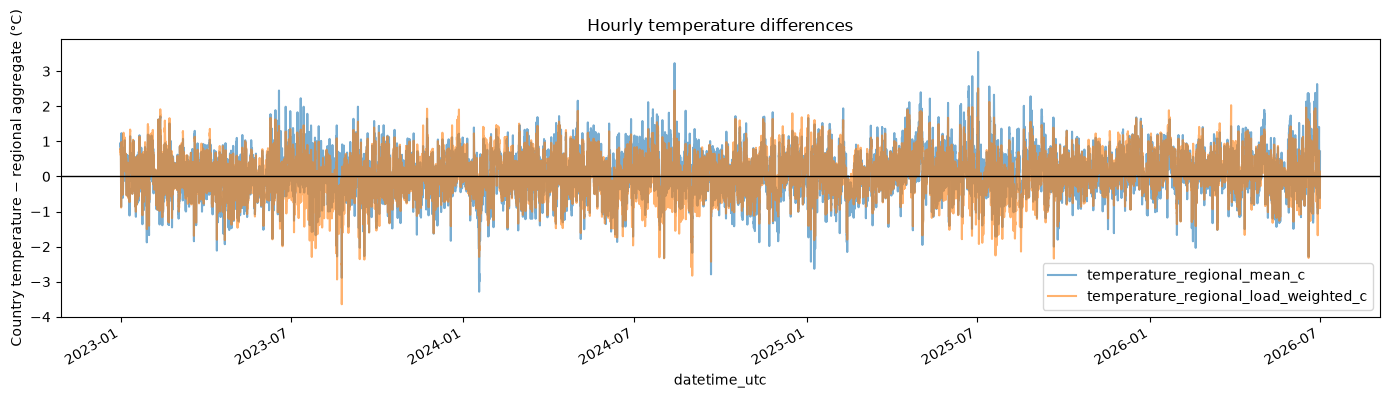

In [16]:
plot_errors = errors.copy()
plot_errors.index = pd.DatetimeIndex(
    comparison.loc[paired.index, "datetime_utc"]
)

ax = plot_errors.plot(
    figsize=(14, 4),
    alpha=0.6,
    ylabel="Country temperature − regional aggregate (°C)",
    title="Hourly temperature differences",
)

ax.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

The regional temperature was missing because the aggregation included only electricity load. Simple and load-weighted regional temperature averages approximate the country temperature but do not reproduce it; the national weighting method remains unknown. Country load nearly equals the regional sum, except for one suspicious 1,620 MW discrepancy. Country load is marginally closer to the day-ahead forecast overall, but removing that hour reverses the hourly ranking, indicating no meaningful accuracy advantage.

In [17]:
df_country.dtypes

datetime_utc                   datetime64[us, UTC]
load_mw                                    float64
rte_forecast_d1_mw                         float64
temperature_c                              float64
datetime_cet          datetime64[us, Europe/Paris]
dtype: object

In [18]:
# EDA
eda = df_country.copy()
eda['hour']= eda['datetime_cet'].dt.hour 
eda['is_weekend'] = eda['datetime_cet'].dt.dayofweek >= 5
profile = eda.groupby(['hour', 'is_weekend'])['load_mw'].agg(['mean','median', 'std', 'min', 'max', 'count'])
profile.head(48)

mean   median           std      min      max  count
hour is_weekend                                                              
0    False       51262.379028  47894.0   9277.998806  37448.0  79932.0   1955
     True        50473.111253  46956.0   9408.541382  37976.0  76682.0    782
1    False       47981.989264  44529.0   9517.333166  34362.0  77602.0   1956
     True        47099.615090  43452.0   9588.399000  34923.0  74288.0    782
2    False       47086.185583  43628.0   9755.368878  33449.0  77018.0   1956
     True        45876.096899  41762.5   9819.312041  34019.0  73959.0    774
3    False       45019.008691  41499.5   9736.652871  31448.0  74980.0   1956
     True        43519.656010  39680.0   9747.128373  31669.0  71432.0    782
4    False       43817.887526  40299.5   9667.467972  30416.0  73592.0   1956
     True        41856.150895  38050.0   9624.357980  30392.0  69772.0    782
5    False       44678.300102  41093.0   9921.780343  30526.0  74296.0   1956
     True        41509.248082  37785.0   9740.444992  30051.0  69784.0    782
6    False       47982.342025  44657.0  10737.886789  30472.0  77682.0   1956
     True        42216.516624  38704.0  10148.281066  29431.0  71408.0    782
7    False       52553.202965  49585.0  11797.010002  31144.0  82864.0   1956
     True        43386.896419  40013.0  10597.393606  29364.0  73806.0    782
8    False       55752.720348  52648.5  11919.616349  32721.0  87372.0   1956
     True        45141.287724  41493.5  10712.726282  30792.0  76086.0    782
9    False       57362.269939  53931.0  11340.611555  35316.0  89498.0   1956
     True        47645.099744  44003.5  10587.300367  33210.0  79128.0    782
10   False       57843.490286  54213.5  10658.930079  37316.0  90210.0   1956
     True        49553.993606  46035.0  10323.520379  35792.0  80221.0    782
11   False       58041.866564  54264.0  10051.951925  38608.0  89254.0   1956
     True        50600.987212  47189.5   9889.456426  38168.0  79838.0    782
12   False       58746.606339  55131.0   9522.038523  40488.0  88387.0   1956
     True        52150.300512  48850.0   9522.841901  40137.0  80550.0    782
13   False       58264.013292  54757.0   9067.430868  41532.0  86964.0   1956
     True        52144.854220  48806.0   9105.409129  39857.0  79560.0    782
14   False       56705.091513  53465.0   8763.449025  39312.0  84344.0   1956
     True        49524.269821  46330.0   8687.024814  37418.0  75533.0    782
15   False       55265.822597  52218.0   8538.515135  37928.0  82710.0   1956
     True        47903.855499  44837.0   8433.836060  35802.0  72882.0    782
16   False       53897.905930  50812.0   8644.973905  36674.0  81316.0   1956
     True        46589.296675  43387.0   8446.214077  34378.0  71836.0    782
17   False       53466.999489  49876.0   9304.506255  36180.0  81928.0   1956
     True        46527.707161  42982.0   9000.310882  33856.0  73332.0    782
18   False       55096.863497  50572.0  10598.731593  37090.0  86347.0   1956
     True        48560.843990  44119.0  10278.924685  34624.0  78044.0    782
19   False       57405.810838  52600.0  11152.401592  38878.0  89416.0   1956
     True        51116.377238  46531.5  10886.760834  36620.0  80740.0    782
20   False       56001.373211  52166.5  10434.256418  38986.0  87174.0   1956
     True        50856.960358  47238.0  10376.456871  36990.0  79260.0    782
21   False       53351.428425  49744.0   9569.714161  38636.0  83074.0   1956
     True        49360.589514  45611.5   9626.215555  36626.0  75896.0    782
22   False       52101.773517  48553.0   8890.750120  39194.0  80710.0   1956
     True        48765.250639  45131.5   9022.497095  38090.0  74484.0    782
23   False       53435.457055  50124.5   8932.233946  40663.0  81123.0   1956
     True        50584.698210  46957.0   9095.553640  39398.0  76920.0    782

We see some inconsistency in Hour 2 for weekends = TRUE , count is 774 but it should be normaly 782 , 8 days missing ! 


In [19]:
curves = (profile[['mean']].unstack('is_weekend').rename(columns={False: 'weekdays', True: 'weekends'}))
curves.head()

mean              
is_weekend      weekdays      weekends
hour                                  
0           51262.379028  50473.111253
1           47981.989264  47099.615090
2           47086.185583  45876.096899
3           45019.008691  43519.656010
4           43817.887526  41856.150895

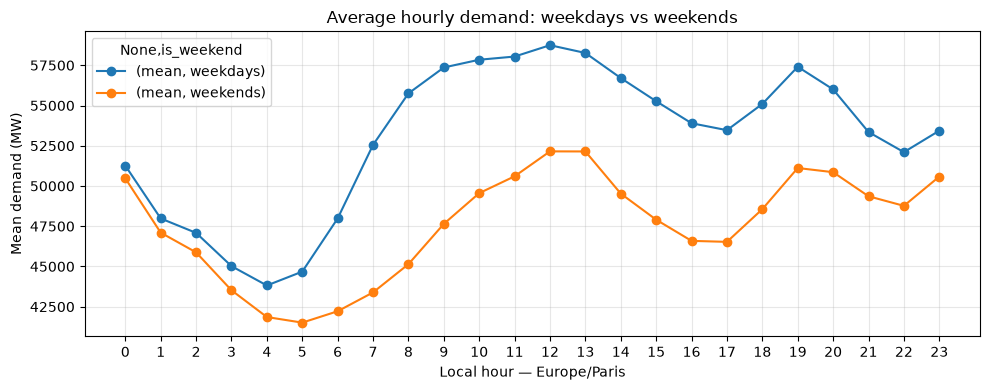

In [20]:

ax = curves.plot(
    figsize=(10, 4),
    marker="o",
    title="Average hourly demand: weekdays vs weekends",
)

ax.set_xlabel("Local hour — Europe/Paris")
ax.set_ylabel("Mean demand (MW)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
gap = curves[('mean', 'weekdays')] - curves[('mean', 'weekends')]
gap.head(24)

hour
0       789.267775
1       882.374174
2      1210.088684
3      1499.352681
4      1961.736630
5      3169.052020
6      5765.825400
7      9166.306546
8     10611.432624
9      9717.170194
10     8289.496680
11     7440.879352
12     6596.305828
13     6119.159072
14     7180.821692
15     7361.967098
16     7308.609255
17     6939.292328
18     6536.019507
19     6289.433601
20     5144.412853
21     3990.838911
22     3336.522878
23     2850.758845
dtype: float64

In [22]:
 # Seasonal demand profiles
eda['month'] = eda['datetime_cet'].dt.month
season_map = {1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring', 6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn', 12: 'Winter'}
eda['season'] = eda['month'].map(season_map)
seasonal = eda.groupby(['season','hour','is_weekend'])['load_mw'].mean()
winter = seasonal.loc['Winter'].unstack('is_weekend').rename(columns={False: 'weekdays', True: 'weekends'})
summer = seasonal.loc['Summer'].unstack('is_weekend').rename(columns={False: 'weekdays', True: 'weekends'})
spring = seasonal.loc['Spring'].unstack('is_weekend').rename(columns={False: 'weekdays', True: 'weekends'})
autumn = seasonal.loc['Autumn'].unstack('is_weekend').rename(columns={False: 'weekdays', True: 'weekends'})
eda["season"].isna().sum()

0

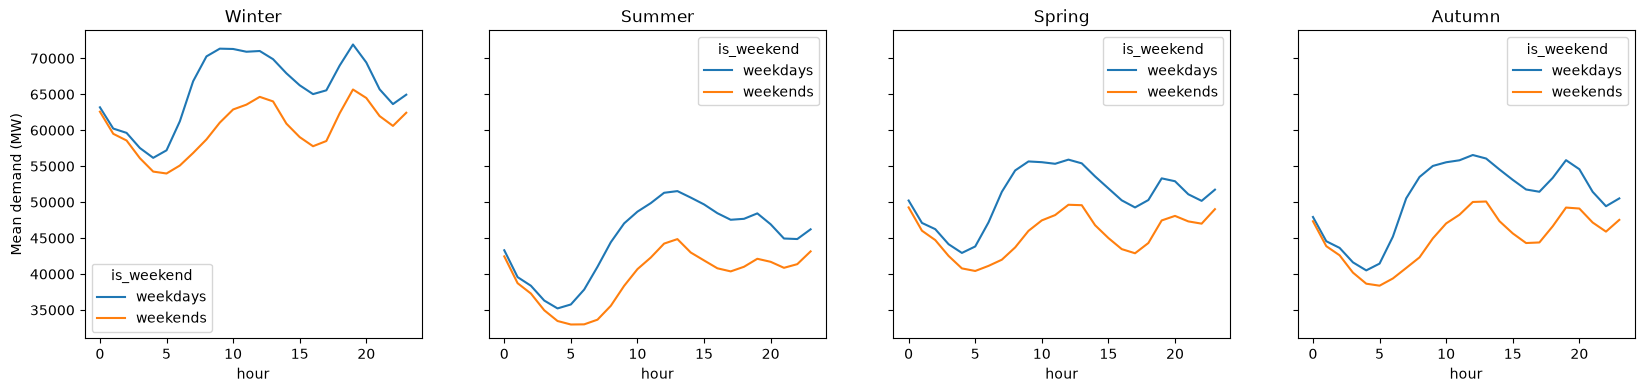

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4),sharex=True, sharey=True)

winter.plot(ax=axes[0], title="Winter")
summer.plot(ax=axes[1], title="Summer")
spring.plot(ax=axes[2], title="Spring")
autumn.plot(ax=axes[3], title="Autumn")
axes[0].set_ylabel("Mean demand (MW)")

plt.show()

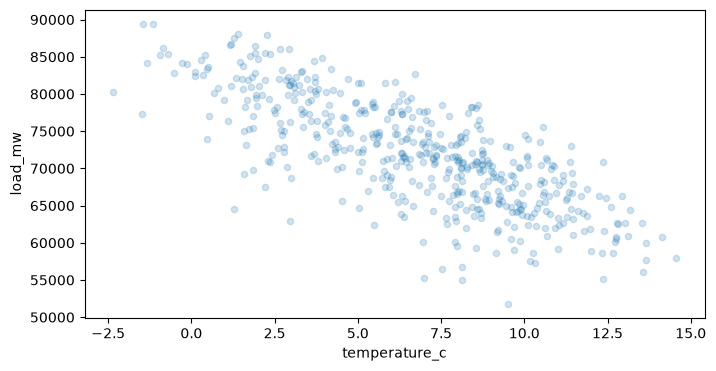

In [24]:
# Temperature and demand

sample = eda.loc[eda['season'].eq('Winter') & eda['is_weekend'].eq(False) & eda['hour'].eq(19)].copy()

sample.plot.scatter(x='temperature_c', y='load_mw', alpha=0.2, figsize=(8, 4))
plt.show()

During winter weekdays at 19:00, demand appears to increase as temperature decrease. A feature worth testing is temperature_c.

In [25]:

# Summarize demand within 2 c band
binned = sample.dropna(subset=['temperature_c','load_mw' ]).copy()
print("Excluded Rows:",len(sample) - len(binned))
temp = binned['temperature_c']
lower = 2 * np.floor(temp.min() / 2)
upper = 2 * np.ceil(temp.max() / 2) 
edges = np.arange(lower, upper, 2)
binned['temp_band'] = pd.cut(binned['temperature_c'], bins=edges, right=False)
summary = binned.groupby('temp_band', observed = False).agg(
    median_load = ('load_mw', 'median'),
    count_observs = ('load_mw', 'count')
)
summary

Excluded Rows: 0


,median_load,count_observs
temp_band,,
"[-4.0, -2.0)",80316.0,1
"[-2.0, 0.0)",84673.0,10
"[0.0, 2.0)",81510.0,44
"[2.0, 4.0)",79370.0,67
"[4.0, 6.0)",74496.0,69
"[6.0, 8.0)",71676.5,104
"[8.0, 10.0)",68694.5,112
"[10.0, 12.0)",66228.0,65
"[12.0, 14.0)",61626.0,21


In [26]:
# Are RTE forecasts systematically too low or too high during colder conditions?

error_sample = sample.dropna(
    subset=["load_mw", "rte_forecast_d1_mw", "temperature_c"]
).copy()



In [27]:
error_sample["rte_error_mw"] = (
    error_sample["load_mw"]
    - error_sample["rte_forecast_d1_mw"]
)

error_sample["absolute_error_mw"] = (
    error_sample["rte_error_mw"].abs()
    
)

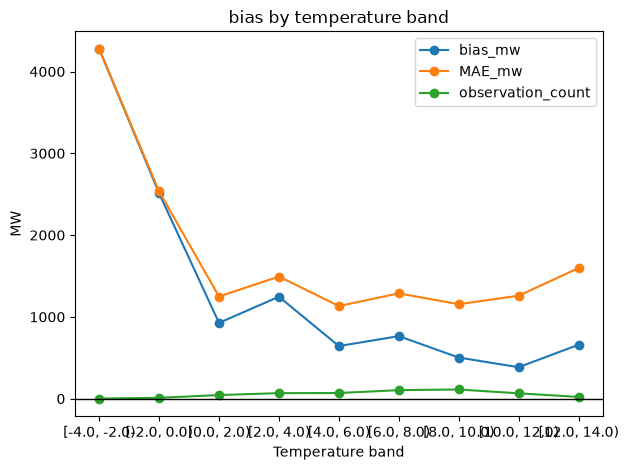

In [41]:
error_sample["temperature_band"] = pd.cut(error_sample["temperature_c"],bins=edges, right=False)
summary_error = error_sample.groupby('temperature_band', observed=False ).agg(
     bias_mw = ('rte_error_mw', 'mean'),
        MAE_mw = ('absolute_error_mw', 'mean'), observation_count = ('rte_error_mw','count') )

ax = summary_error.plot(marker="o"
    ,
    title="bias by temperature band",
)

ax.set_xlabel("Temperature band")
ax.set_ylabel("MW")



ax.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

,bias_mw,MAE_mw,observation_count
temperature_band,,,
"[-4.0, -2.0)",4278.000000,4278.000000,1
"[-2.0, 0.0)",2512.200000,2534.400000,10
"[0.0, 2.0)",926.500000,1248.590909,44
"[2.0, 4.0)",1246.537313,1492.865672,67
"[4.0, 6.0)",643.014493,1132.202899,69
